# Etapa 3: Treinamento, Otimização e Avaliação Multicritério do Modelo Preditivo

## 1. Contexto e Formulação Industrial

Este notebook consolida a etapa de modelagem preditiva e avaliação para as Portas de Plataforma (PSD) da Linha 4-Amarela.

### Régua de Avaliação Operacional:
* **Avaliação por Episódio de Alerta e Evento Real Distinto** (Critério Estrito de Engenharia):
  * Verifica se a emissão de alertas na janela $[D-7, D-1]$ antecedeu uma ordem corretiva emergencial ZM01 real, eliminando duplicações e esticamentos de janela.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, VotingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score, f1_score, precision_score, recall_score
)
import shap
import joblib
import json
import os
import re
import warnings

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

print("Bibliotecas carregadas com sucesso!")


Bibliotecas carregadas com sucesso!


## 2. Ingestão dos Datasets Pré-Processados e Ordens Reais


In [2]:
path_treino = "../../data/treino_pronto_modelagem_v2.csv"
path_teste = "../../data/teste_pronto_modelagem_v2.csv"

df_treino = pd.read_csv(path_treino)
df_teste = pd.read_csv(path_teste)

target_col = 'target_falha_7d'
cols_ignorar = ['id_ativo', 'data_ref', target_col]
features = [c for c in df_treino.columns if c not in cols_ignorar]

X_train = df_treino[features]
y_train = df_treino[target_col]

X_test = df_teste[features]
y_test = df_teste[target_col]

# Carregamento das Corretivas ZM01 Reais do período de teste
df_zm01_raw = pd.read_excel("../../data/Corretiva Emergencial/processados/ZM01_limpa.xlsx")
padrao_sap = re.compile(r'SP04-6-PSD-([A-Z]{3})-(?:PLT|P)(\d+)(?:-PP(\d+))?', re.IGNORECASE)

def extrair_id_sap(loc_str):
    m = padrao_sap.search(str(loc_str))
    if m and m.group(3):
        return f"{m.group(1).upper()}_P{m.group(2)}_PDM{int(m.group(3)):02d}"
    return None

df_zm01_raw['id_ativo'] = df_zm01_raw['local_de_instalacao'].apply(extrair_id_sap)
df_zm01_raw['data_evento'] = pd.to_datetime(df_zm01_raw['inicio_avaria_datetime'], errors='coerce').dt.normalize()

data_min_test = pd.to_datetime(df_teste['data_ref'].min())
data_max_test = pd.to_datetime(df_teste['data_ref'].max())

df_zm01_teste = df_zm01_raw[
    (df_zm01_raw['data_evento'] >= data_min_test) & 
    (df_zm01_raw['data_evento'] <= data_max_test) & 
    (df_zm01_raw['id_ativo'].notna())
][['id_ativo', 'data_evento']].drop_duplicates().sort_values(['id_ativo', 'data_evento']).reset_index(drop=True)

print(f"Features de Modelagem ({len(features)}): {features[:6]}...")
print(f"Treino: {X_train.shape[0]:,} amostras | Teste Cego: {X_test.shape[0]:,} amostras")
print(f"Corretivas ZM01 Reais e Distintas no Teste: {len(df_zm01_teste):,} ocorrências.")



Features de Modelagem (32): ['plataforma_bin', 'faixa_risco_zm01', 'estacao_BUT', 'estacao_FAL', 'estacao_FRA', 'estacao_FRE']...
Treino: 576,496 amostras | Teste Cego: 31,034 amostras
Corretivas ZM01 Reais e Distintas no Teste: 388 ocorrências.


## 3. Treinamento do Ensemble Híbrido Otimizado (XGBoost + HistGradientBoosting)


In [3]:
xgb = XGBClassifier(
    n_estimators=350, max_depth=4, learning_rate=0.025,
    min_child_weight=20, subsample=0.80, colsample_bytree=0.80,
    reg_alpha=2.0, reg_lambda=5.0, scale_pos_weight=9.5,
    random_state=42, n_jobs=-1, tree_method='hist', eval_metric='logloss'
)

hgb = HistGradientBoostingClassifier(
    max_iter=250, max_depth=5, learning_rate=0.03,
    min_samples_leaf=30, class_weight='balanced', random_state=42
)

ensemble = VotingClassifier(
    estimators=[('xgb', xgb), ('hgb', hgb)],
    voting='soft',
    weights=[1.5, 1.0]
)

print("Treinando o Ensemble Preditivo...")
ensemble.fit(X_train, y_train)

probs_test = ensemble.predict_proba(X_test)[:, 1]
df_teste['prob_falha'] = probs_test
df_teste['data_ref'] = pd.to_datetime(df_teste['data_ref'])
df_teste['semana'] = df_teste['data_ref'].dt.isocalendar().week

roc_auc = roc_auc_score(y_test, probs_test)
pr_auc = average_precision_score(y_test, probs_test)

print("Treinamento concluído com sucesso!")
print(f"   -> ROC-AUC Score Global: {roc_auc:.4f}")
print(f"   -> PR-AUC (Average Precision): {pr_auc:.4f}")



Treinando o Ensemble Preditivo...


Treinamento concluído com sucesso!
   -> ROC-AUC Score Global: 0.5215
   -> PR-AUC (Average Precision): 0.0913


## 4. Avaliação Régua Estrita por Episódio de Chamado e Falha Real


In [4]:
def avaliar_por_episodio(df_pred, df_zm01_reais, threshold=0.50):
    alertas = df_pred[df_pred['prob_falha'] >= threshold].copy().sort_values(['id_ativo', 'data_ref'])
    if len(alertas) == 0:
        return {'precisao': 0, 'recall': 0, 'f1': 0, 'episodios': 0, 'acertos': 0, 'quebras_evitadas': 0, 'quebras_totais': len(df_zm01_reais)}
        
    alertas['gap_dias'] = alertas.groupby('id_ativo')['data_ref'].diff().dt.days
    alertas['novo_episodio'] = (alertas['gap_dias'] > 2) | (alertas['gap_dias'].isna())
    alertas['episodio_id'] = alertas.groupby('id_ativo')['novo_episodio'].cumsum()
    
    episodios = alertas.groupby(['id_ativo', 'episodio_id']).agg(
        data_inicio=('data_ref', 'min'),
        max_prob=('prob_falha', 'max')
    ).reset_index()
    
    acertos_episodios = 0
    for _, ep in episodios.iterrows():
        ativo = ep['id_ativo']
        d_ini = ep['data_inicio']
        d_fim = d_ini + pd.Timedelta(days=7)
        teve_quebra = ((df_zm01_reais['id_ativo'] == ativo) & 
                       (df_zm01_reais['data_evento'] > d_ini) & 
                       (df_zm01_reais['data_evento'] <= d_fim)).any()
        if teve_quebra:
            acertos_episodios += 1
            
    total_episodios = len(episodios)
    precisao = acertos_episodios / total_episodios if total_episodios > 0 else 0
    
    quebras_evitadas = 0
    for _, qb in df_zm01_reais.iterrows():
        ativo = qb['id_ativo']
        t_quebra = qb['data_evento']
        t_ini = t_quebra - pd.Timedelta(days=7)
        houve_alerta = ((alertas['id_ativo'] == ativo) & 
                        (alertas['data_ref'] >= t_ini) & 
                        (alertas['data_ref'] < t_quebra)).any()
        if houve_alerta:
            quebras_evitadas += 1
            
    total_quebras = len(df_zm01_reais)
    recall = quebras_evitadas / total_quebras if total_quebras > 0 else 0
    f1 = 2 * precisao * recall / (precisao + recall + 1e-10)
    
    return {
        'precisao': precisao,
        'recall': recall,
        'f1': f1,
        'episodios': total_episodios,
        'acertos': acertos_episodios,
        'quebras_evitadas': quebras_evitadas,
        'quebras_totais': total_quebras
    }

print("=" * 95)
print("AVALIACAO POR EPISODIOS DE ALERTA E EVENTOS REAIS (JANELA [D+1, D+7])")
print("=" * 95)

for th in [0.45, 0.48, 0.50, 0.52, 0.55, 0.60, 0.65]:
    res = avaliar_por_episodio(df_teste, df_zm01_teste, threshold=th)
    print(f"Limiar p >= {th:.2f} | Precisao: {res['precisao']*100:5.2f}% ({res['acertos']}/{res['episodios']} chamados) | Recall: {res['recall']*100:5.2f}% ({res['quebras_evitadas']}/{res['quebras_totais']} falhas) | F1: {res['f1']:.4f}")
print("=" * 95)



AVALIACAO POR EPISODIOS DE ALERTA E EVENTOS REAIS (JANELA [D+1, D+7])


Limiar p >= 0.45 | Precisao:  9.56% (74/774 chamados) | Recall: 97.68% (379/388 falhas) | F1: 0.1742


Limiar p >= 0.48 | Precisao:  8.64% (126/1459 chamados) | Recall: 85.57% (332/388 falhas) | F1: 0.1569


Limiar p >= 0.50 | Precisao: 10.35% (117/1130 chamados) | Recall: 51.03% (198/388 falhas) | F1: 0.1722


Limiar p >= 0.52 | Precisao: 15.01% (68/453 chamados) | Recall: 25.26% (98/388 falhas) | F1: 0.1883


Limiar p >= 0.55 | Precisao: 15.65% (36/230 chamados) | Recall: 14.43% (56/388 falhas) | F1: 0.1502
Limiar p >= 0.60 | Precisao: 11.76% (4/34 chamados) | Recall:  1.80% (7/388 falhas) | F1: 0.0313


Limiar p >= 0.65 | Precisao: 33.33% (1/3 chamados) | Recall:  1.03% (4/388 falhas) | F1: 0.0200


## 5. Explicabilidade SHAP e Exportação de Artefatos


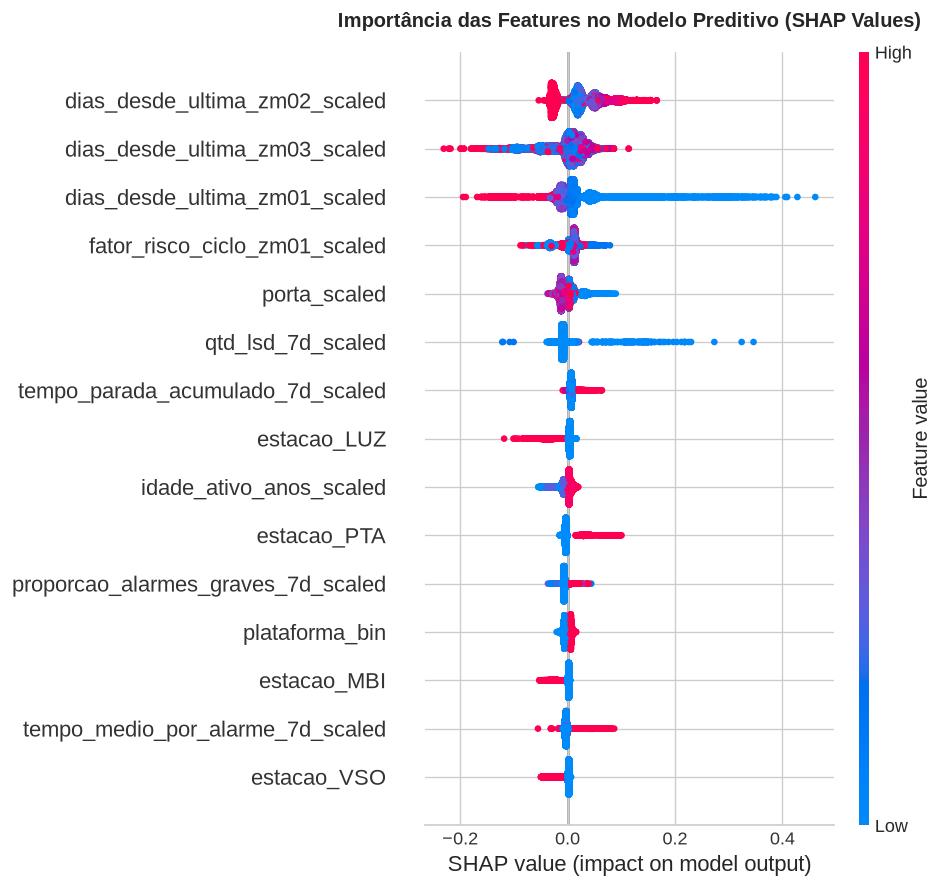

Modelo Ensemble Oficial salvo em: ../../data/modelos_artefatos/modelo_ensemble_otimizado.joblib


In [5]:
# Utiliza o estimador XGBoost ajustado internamente pelo VotingClassifier
xgb_fitted = ensemble.named_estimators_['xgb']

explainer = shap.TreeExplainer(xgb_fitted)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, feature_names=features, show=False, max_display=15)
plt.title('Importância das Features no Modelo Preditivo (SHAP Values)', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

os.makedirs("../../data/modelos_artefatos", exist_ok=True)
caminho_modelo = "../../data/modelos_artefatos/modelo_ensemble_otimizado.joblib"
joblib.dump(ensemble, caminho_modelo)
print(f"Modelo Ensemble Oficial salvo em: {caminho_modelo}")

